In [1]:
import pandas as pd
import matplotlib.pyplot as plt

housing_df = pd.read_csv("Housing.csv")
income_df = pd.read_csv("Income.csv")

In [2]:
def clean_money(val):
    if pd.isna(val):
        return None

    clean_str = str(val).replace('$', '').replace(',', '').strip()

    try:
        return float(clean_str)
    except ValueError:
        return None


housing_df['Clean_Home_Value'] = housing_df[
    'Median Home  Value (2010)'
].apply(clean_money)

In [3]:
valid_housing = housing_df.dropna(subset=['Clean_Home_Value'])

valid_housing = valid_housing[
    valid_housing['Clean_Home_Value'] > 0
]

income_df["2009 Median Income ('09 Dollars)"] = income_df[
    "2009 Median Income ('09 Dollars)"
].apply(clean_money)

merged_df = pd.merge(
    income_df,
    valid_housing[['Neighborhood', 'Clean_Home_Value']],
    on='Neighborhood'
)

merged_df = merged_df.dropna(
    subset=["2009 Median Income ('09 Dollars)"]
)

merged_df = merged_df[
    merged_df["2009 Median Income ('09 Dollars)"] > 0
]

# Check how many neighborhoods were matched
print("Income neighborhoods:", income_df['Neighborhood'].nunique())
print("Housing neighborhoods:", housing_df['Neighborhood'].nunique())
print("Matched neighborhoods:", merged_df['Neighborhood'].nunique())

Income neighborhoods: 90
Housing neighborhoods: 90
Matched neighborhoods: 85


In [4]:
merged_df['Affordability_Score'] = (
    merged_df["2009 Median Income ('09 Dollars)"] /
    merged_df['Clean_Home_Value']
)

final_sorted = merged_df[
    ['Neighborhood', 'Affordability_Score']
].sort_values(
    by='Affordability_Score',
    ascending=False
)

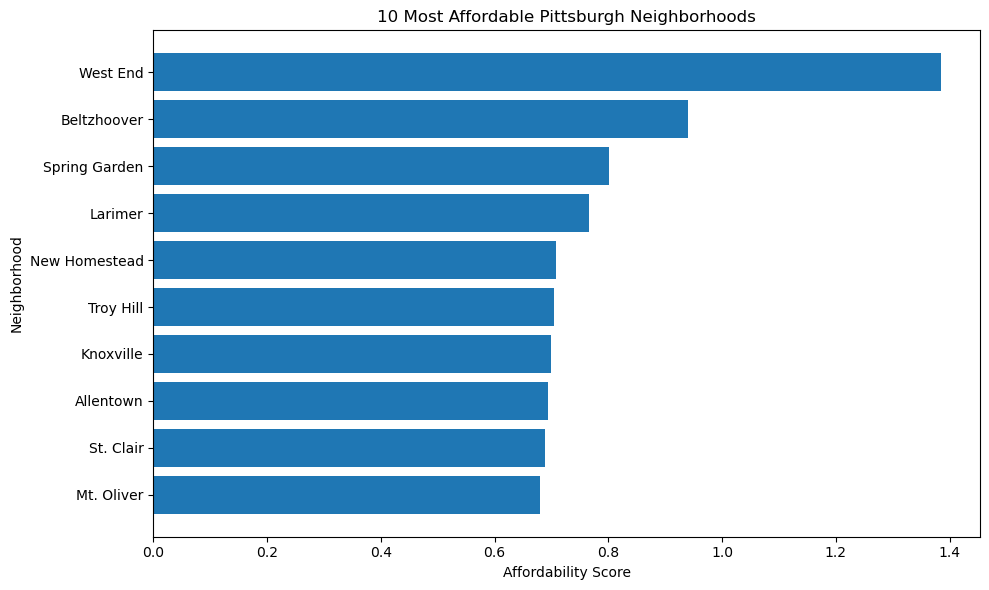

In [5]:
top_10 = final_sorted.head(10).sort_values(
    by='Affordability_Score'
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10['Neighborhood'],
    top_10['Affordability_Score']
)

plt.xlabel('Affordability Score')
plt.ylabel('Neighborhood')
plt.title('10 Most Affordable Pittsburgh Neighborhoods')

plt.tight_layout()
plt.show()

In [6]:
print("PITTSBURGH NEIGHBORHOOD AFFORDABILITY RANKINGS")
print("----------------------------------------------")

print(
    final_sorted.to_string(
        index=False,
        formatters={'Affordability_Score': '{:.3f}'.format}
    )
)

PITTSBURGH NEIGHBORHOOD AFFORDABILITY RANKINGS
----------------------------------------------
             Neighborhood Affordability_Score
                 West End               1.384
              Beltzhoover               0.941
            Spring Garden               0.800
                  Larimer               0.765
            New Homestead               0.708
                Troy Hill               0.705
                Knoxville               0.699
                Allentown               0.694
                St. Clair               0.689
               Mt. Oliver               0.679
 Lincoln-Lemington-Belmar               0.675
           Swisshelm Park               0.668
      Upper Lawrenceville               0.653
            East Carnegie               0.642
                Ridgemont               0.622
              Perry North               0.606
                    Bluff               0.604
           Homewood North               0.597
                     Hays       